# WEEK 5 - Mid Review

## Social Media Usage, Productivity & Digital Well-Being Analysis

### Mid-Review: Data Audit

This notebook summarizes the work completed from Week 1 to Week 4,
including dataset understanding, data cleaning, exploratory data analysis
and key statistical findings.

## Problem Statement

Excessive and unbalanced social media usage may be associated with reduced
productivity, inadequate sleep, increased stress and burnout.

This project analyses social media usage patterns and studies their
relationship with productivity and digital well-being using data science
and visualization techniques.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "Dataset/social_media_vs_productivity_modified_clean.csv"
)
print("Cleaned dataset loaded successfully!")
print("Dataset shape:", df.shape)

Cleaned dataset loaded successfully!
Dataset shape: (30000, 19)


## Dataset Overview

The project uses a social media and productivity dataset containing
30,000 records and 19 attributes.

The dataset includes information related to:

- User demographics
- Social media usage
- Platform preference
- Productivity
- Stress
- Sleep
- Burnout
- Job satisfaction
- Digital well-being behaviour

Both the raw and cleaned datasets are maintained separately to preserve
the original data and support reproducible analysis.

In [10]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])
print("Total Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

Number of Rows: 30000
Number of Columns: 19
Total Missing Values: 0
Duplicate Rows: 0


## Data Quality Improvement

The raw dataset contained missing values in several numerical attributes.

During Week 3, suitable imputation techniques were applied to improve data
quality while retaining all records.

In [11]:
raw_df = pd.read_csv("Dataset/social_media_vs_productivity.csv")

quality_comparison = pd.DataFrame({
    "Metric": [
        "Rows",
        "Columns",
        "Missing Values",
        "Duplicate Rows"
    ],
    "Before Cleaning": [
        raw_df.shape[0],
        raw_df.shape[1],
        raw_df.isnull().sum().sum(),
        raw_df.duplicated().sum()
    ],
    "After Cleaning": [
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        df.duplicated().sum()
    ]
})

quality_comparison

,Metric,Before Cleaning,After Cleaning
0,Rows,30000,30000
1,Columns,19,19
2,Missing Values,16187,0
3,Duplicate Rows,0,0


### Observation

The cleaning process successfully removed all missing values while preserving
all 30,000 records.

No duplicate rows were present in either the raw or cleaned dataset.

## Week-wise Project Progress

### Week 1 - Project Setup and Dataset Selection
- Finalized the project problem statement and objectives.
- Selected the Social Media vs Productivity dataset.
- Set up the project repository in GitHub.
- Introduced Pandas and NumPy for data handling.

### Week 2 - Know Your Data
- Loaded and inspected the raw dataset.
- Identified 30,000 rows and 19 attributes.
- Checked data types, structure and descriptive statistics.
- Identified missing values and duplicate records.
- Generated the First Impression Report.

### Week 3 - Cleaning Sprint
- Created a separate copy of the raw dataset for cleaning.
- Handled missing values using suitable imputation techniques.
- Detected potential outliers using boxplots and Z-scores.
- Retained valid extreme observations after inspection.
- Generated a Data Quality Report.
- Saved the cleaned dataset separately.

### Week 4 - EDA Deep Dive
- Performed univariate analysis.
- Performed bivariate analysis.
- Visualized numerical and categorical distributions.
- Analysed relationships between social media usage, productivity,
  sleep, stress and other digital well-being factors.
- Generated a correlation heatmap and extracted key findings.

## Methodology Followed

Raw Dataset

↓

Data Understanding

↓

Missing Value and Duplicate Inspection

↓

Data Cleaning and Imputation

↓

Outlier Detection

↓

Cleaned Dataset

↓

Univariate Analysis

↓

Bivariate Analysis

↓

Correlation Analysis

↓

Key Insights

## Key Visualization 1 - Daily Social Media Usage Distribution

This visualization shows the overall distribution of daily social media usage
among users.

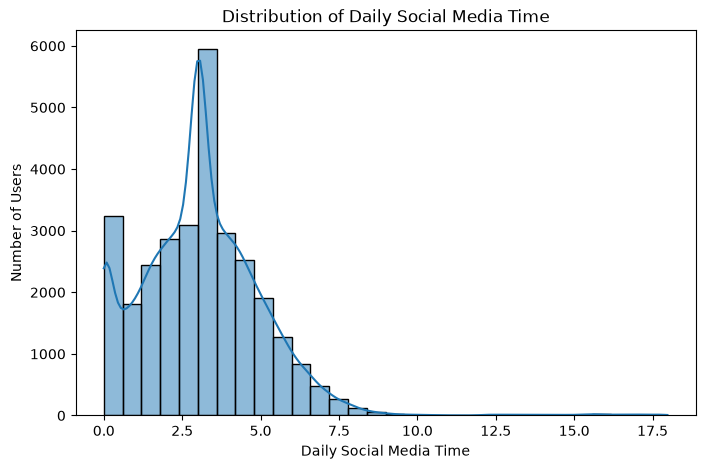

In [12]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="daily_social_media_time",
    bins=30,
    kde=True
)

plt.title("Distribution of Daily Social Media Time")
plt.xlabel("Daily Social Media Time")
plt.ylabel("Number of Users")

plt.show()

### Observation

The distribution is positively skewed.

Most users show moderate social media usage, while a smaller number of users
have unusually high usage.

## Key Visualization 2 - Social Media Usage vs Actual Productivity

A scatter plot with a regression line is used to study the relationship
between daily social media usage and actual productivity.

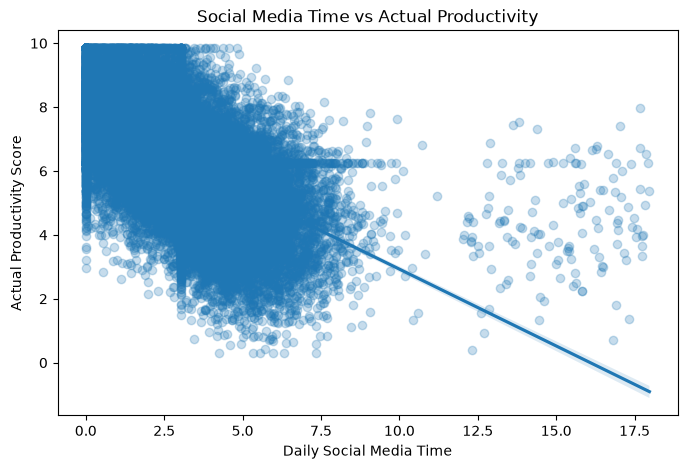

Correlation: -0.55


In [13]:
plt.figure(figsize=(8,5))

sns.regplot(
    data=df,
    x="daily_social_media_time",
    y="actual_productivity_score",
    scatter_kws={"alpha":0.25}
)

plt.title("Social Media Time vs Actual Productivity")
plt.xlabel("Daily Social Media Time")
plt.ylabel("Actual Productivity Score")

plt.show()

corr_productivity = df["daily_social_media_time"].corr(
    df["actual_productivity_score"]
)

print("Correlation:", round(corr_productivity, 2))

### Observation

The scatter plot and regression line show the relationship between social
media usage and actual productivity.

The correlation value helps determine whether the relationship is positive,
negative or weak.

## Key Visualization 3 - Social Media Usage vs Sleep Hours

A hexbin plot is used to analyse the relationship between daily social media
usage and sleep duration.

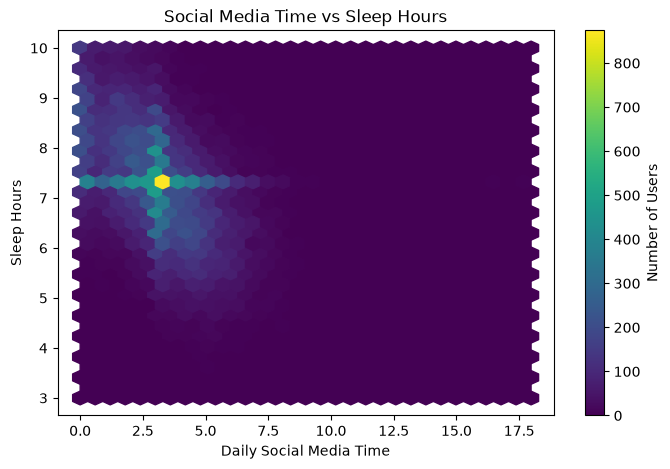

Correlation: -0.49


In [14]:
plt.figure(figsize=(8,5))

plt.hexbin(
    df["daily_social_media_time"],
    df["sleep_hours"],
    gridsize=30,
    cmap="viridis"
)

plt.colorbar(label="Number of Users")

plt.title("Social Media Time vs Sleep Hours")
plt.xlabel("Daily Social Media Time")
plt.ylabel("Sleep Hours")

plt.show()

corr_sleep = df["daily_social_media_time"].corr(df["sleep_hours"])

print("Correlation:", round(corr_sleep, 2))

### Observation

The hexbin plot shows how users are concentrated across different levels
of social media usage and sleep duration.

The correlation value indicates the direction and strength of the
relationship between the two variables.

## Key Visualization 4 - Job Satisfaction vs Actual Productivity

A scatter plot is used to study whether job satisfaction is associated
with actual productivity.

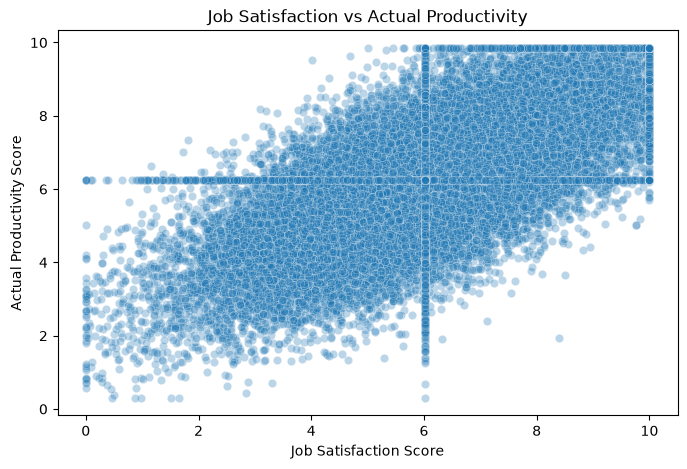

Correlation: 0.67


In [15]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="job_satisfaction_score",
    y="actual_productivity_score",
    alpha=0.3
)

plt.title("Job Satisfaction vs Actual Productivity")
plt.xlabel("Job Satisfaction Score")
plt.ylabel("Actual Productivity Score")

plt.show()

corr_job = df["job_satisfaction_score"].corr(
    df["actual_productivity_score"]
)

print("Correlation:", round(corr_job, 2))

### Observation

The scatter plot shows the relationship between job satisfaction and
actual productivity.

A stronger upward pattern indicates that higher job satisfaction tends
to be associated with higher productivity.

## Key Visualization 5 - Correlation Heatmap

The correlation heatmap summarizes the relationships between all numerical
attributes in the cleaned dataset.

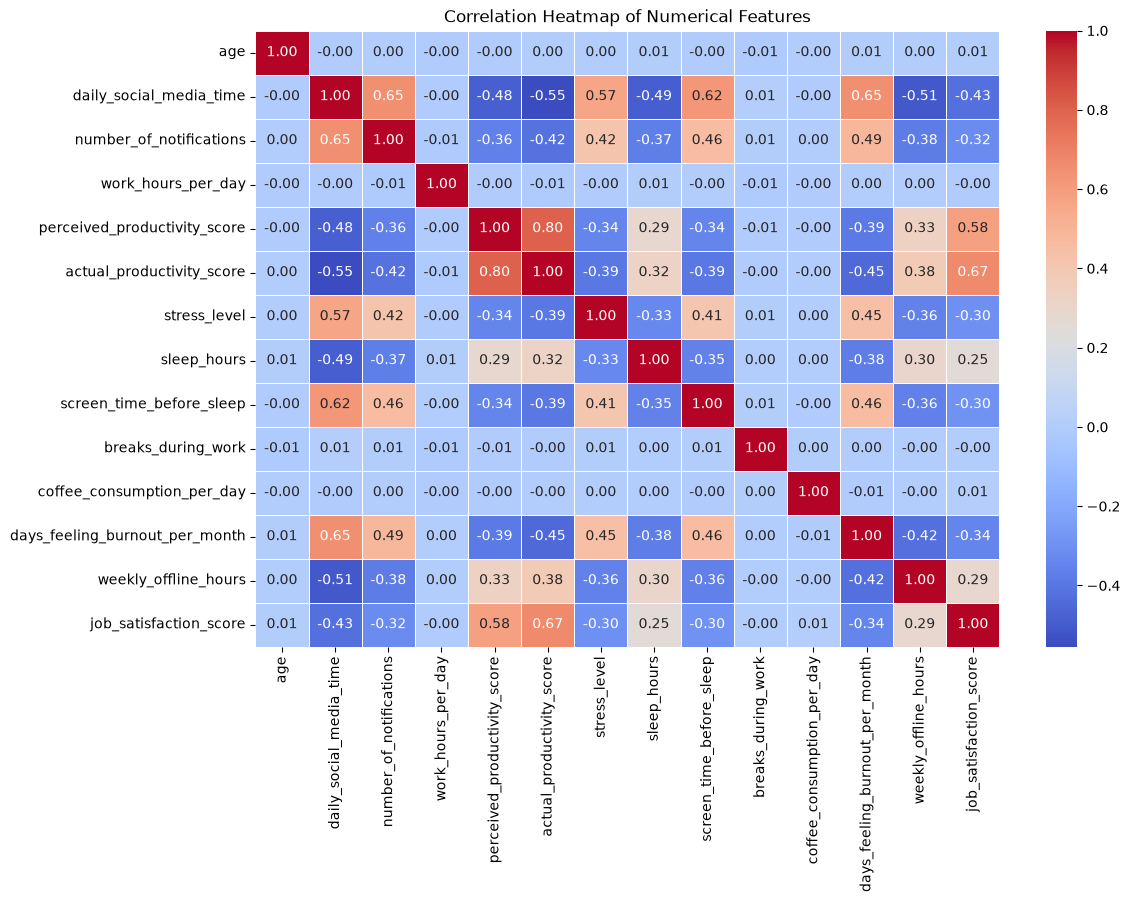

In [16]:
numeric_df = df.select_dtypes(include=["int64", "float64"])

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(12,8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")

plt.show()

### Observation

The heatmap provides an overall view of the positive, negative and weak
relationships among numerical features.

It helps identify the variables that have the strongest relationships
with productivity and digital well-being.

## Initial Statistical Findings

- Daily social media usage follows a positively skewed distribution.
- A smaller group of users shows unusually high social media usage.
- Relationships between social media usage, productivity, sleep and stress
  were examined using bivariate analysis.
- Job satisfaction and productivity were also compared to identify important
  behavioural relationships.
- The correlation heatmap was used to identify the strongest numerical
  relationships in the dataset.
- These findings will be used in the next stage for feature engineering,
  scaling and further analysis.